# Linear regression: predicting baseflow

This notebook uses what we learned in `eda_extra.ipynb` to build linear regression models.

1. **The ladder (models 0–9):** start simple and add one idea at a time, to see what helps.
2. **All features combined:** check whether adding everything beats the best ladder model.
3. **Checking the best model:** plots of predictions and errors.

## Setup

What we do before modeling, based on the EDA:

- **Remove the 9 stations with fake zeros** (all inputs always 0).
- **Use `station`** (segment + location) instead of `segment_id`.
- **Fix the month labels** (date + 16 days).
- **Split by time:** train on 1939–1989, test on 1990–2000. We don't split randomly, because neighboring months are almost copies.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor
from pathlib import Path

file_path = next(p for p in ["data/RRCA_baseflow.csv", "RRCA_baseflow.csv"] if Path(p).exists())
df = pd.read_csv(file_path)
df.columns = df.columns.str.strip()
df = df.rename(columns={
    "Segment_id": "segment_id",
    "Evapotranspiration": "et",
    "Precipitation": "precip",
    "Irrigation_pumping": "pump",
    "Observed": "observed"
})

# Dates: instructor's conversion, then +16 days to fix the month labels
df["date"] = pd.Timestamp("1900-01-01") + pd.to_timedelta(df["Date"] - 693963 + 16, unit="D")
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month

# Station = segment + location
df["station"] = df["segment_id"].astype(str) + "_" + df["x"].astype(str)

# Remove stations where all inputs are always 0 (missing data)
fake_zero = df.groupby("station")["precip"].transform(lambda s: (s == 0).all())
df = df[~fake_zero].copy()

# Log target (log of negative numbers doesn't work, so negatives become 0 first)
df["log_observed"] = np.log1p(df["observed"].clip(lower=0))

# Year trend: years since 1940
df["t"] = df["year"] - 1940

df = df.sort_values(["station", "date"]).reset_index(drop=True)
print(f"Rows: {len(df):,}   Stations: {df['station'].nunique()}")

ModuleNotFoundError: No module named 'statsmodels'

In [ ]:
train = df[df["year"] <= 1989].copy()
test = df[(df["year"] >= 1990) & df["station"].isin(train["station"].unique())].copy()

print(f"Train: {len(train):,} rows (1939-1989)")
print(f"Test:  {len(test):,} rows (1990-2000)")

Train: 9,511 rows (1939-1989)
Test:  1,683 rows (1990-2000)


## How we score the models

We use the same scores as the paper, always on the **test years** (1990–2000) that the model never saw:

- **NSE:** 1 = perfect, 0 = no better than guessing the average, below 0 = worse than guessing the average
- **MAE:** the average size of the error
- **PBIAS:** negative = guesses too high, positive = guesses too low
- **DW (Durbin–Watson):** checks whether errors in neighboring months are linked. 2 = not linked, near 0 = strongly linked.

For log models, we turn the predictions back into normal baseflow before scoring, so every model is scored the same way.

In [ ]:
def scores(actual, predicted):
    error = actual - predicted
    return {
        "NSE": 1 - (error ** 2).sum() / ((actual - actual.mean()) ** 2).sum(),
        "MAE": error.abs().mean(),
        "PBIAS": 100 * error.sum() / actual.sum(),
    }

results = []
models = {}

def fit(name, formula, log=False, train=train, test=test):
    target = "log_observed" if log else "observed"
    model = smf.ols(f"{target} ~ {formula}", data=train).fit()
    back = np.expm1 if log else (lambda v: v)
    s_train = scores(train["observed"], back(model.predict(train)))
    s_test = scores(test["observed"], back(model.predict(test)))
    results.append({
        "model": name,
        "parameters": int(model.df_model),
        "train_NSE": s_train["NSE"],
        "test_NSE": s_test["NSE"],
        "test_MAE": s_test["MAE"],
        "test_PBIAS": s_test["PBIAS"],
        "DW": durbin_watson(model.resid),
    })
    models[name] = model
    return model

## Part 1: The ladder

Each model adds one idea to the one before. Comparing neighbors shows what each idea adds.

| Model | What it adds |
|---|---|
| 0 | Nothing: always guess the training average |
| 1 | Rain, ET and pumping |
| 2 | Location (x, y) |
| 3 | Which station it is (instead of inputs) |
| 4 | Month (season) |
| 5 | Rain, ET and pumping |
| 6 | Year trend (the slow decline) |
| 7 | Same as 4, but predicting the **log** of baseflow |
| 8 | Same as 5, on the log scale |
| 9 | Same as 6, on the log scale |

In [ ]:
fit("0 average only",                      "1")
fit("1 rain + ET + pumping",               "et + precip + pump")
fit("2 + location (x, y)",                 "et + precip + pump + x + y")
fit("3 station",                           "C(station)")
fit("4 station + month",                   "C(station) + C(month)")
fit("5 station + month + inputs",          "C(station) + C(month) + et + precip + pump")
fit("6 + year trend",                      "C(station) + C(month) + et + precip + pump + t")
fit("7 LOG station + month",               "C(station) + C(month)", log=True)
fit("8 LOG station + month + inputs",      "C(station) + C(month) + et + precip + pump", log=True)
fit("9 LOG + year trend",                  "C(station) + C(month) + et + precip + pump + t", log=True)

ladder = pd.DataFrame(results).set_index("model")
ladder.round(3)

,parameters,train_NSE,test_NSE,test_MAE,test_PBIAS,DW
model,,,,,,
0 average only,0,0.000,-1.224,23.145,-110.961,0.047
1 rain + ET + pumping,3,0.035,-1.734,24.317,-107.033,0.054
"2 + location (x, y)",5,0.053,-2.493,27.201,-118.295,0.053
3 station,35,0.800,0.623,6.475,-19.921,0.254
4 station + month,46,0.809,0.590,7.797,-20.630,0.251
5 station + month + inputs,49,0.813,0.441,9.046,-21.270,0.261
6 + year trend,50,0.814,0.461,8.855,13.162,0.263
7 LOG station + month,46,0.828,0.650,6.095,-16.347,0.249
8 LOG station + month + inputs,49,0.856,0.602,6.380,-18.634,0.280


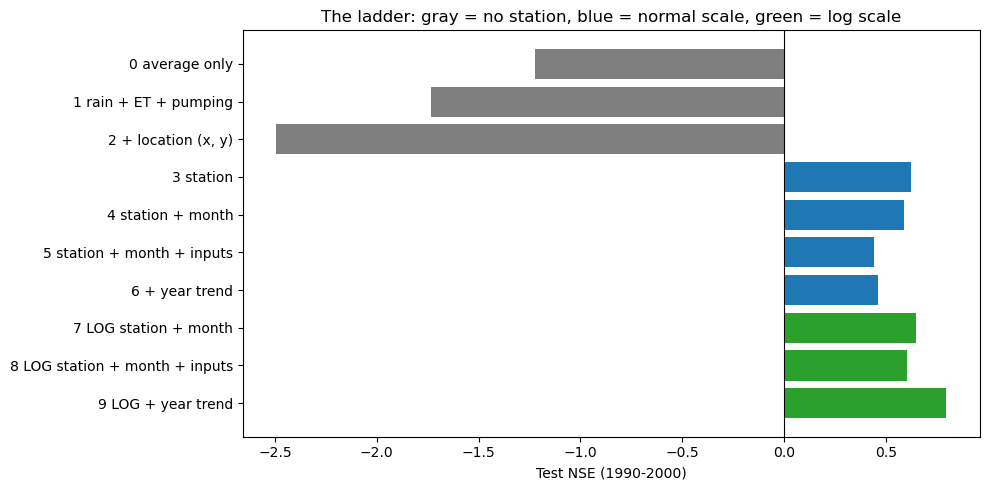

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
colors = ["tab:gray"] * 3 + ["tab:blue"] * 4 + ["tab:green"] * 3
ax.barh(ladder.index[::-1], ladder["test_NSE"][::-1], color=colors[::-1])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Test NSE (1990-2000)")
ax.set_title("The ladder: gray = no station, blue = normal scale, green = log scale")
plt.tight_layout()
plt.show()

### What the ladder shows

- **Models 0–2:** rain, ET, pumping and location alone are **worse than guessing the average**. A big river and a small creek with the same rain have very different baseflow, so these inputs can't work without knowing which river it is.
- **Model 3:** knowing **which station** it is makes the biggest jump (test NSE about 0.62).
- **Models 4–6:** on the normal scale, adding the month or the inputs makes test scores **worse**. The model adds the same amount to every river, which fits neither big rivers nor small creeks.
- **Models 7–9:** on the **log scale**, effects act like percentages ("August is 30% lower"), which works for rivers of every size.
- **Model 9 is the best** (test NSE about 0.80, bias only about +3%). The year trend lets it expect the lower 1990s.

### What model 9 says about each input

On the log scale, each coefficient can be read as a **percentage change** in baseflow.

Pumping is stored as a **negative** number (water removed), so a positive pumping coefficient means **more pumping → less baseflow**.

,coefficient,p_value,% change per 1 unit
ET,-0.0342,0.0,-3.3609
Precipitation,0.0212,0.0,2.1384
Pumping (1 unit LESS pumping),0.0939,0.0,9.8456
Year trend (per year),-0.0079,0.0,-0.7840


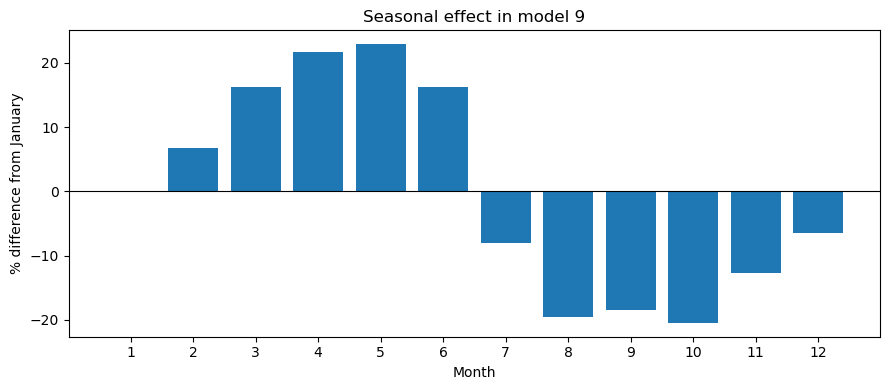

VIF (overlap between inputs, below 5 is fine): {'et': 1.28, 'precip': 1.01, 'pump': 1.37, 't': 1.11}


In [ ]:
m9 = models["9 LOG + year trend"]
inputs = ["et", "precip", "pump", "t"]
table = pd.DataFrame({
    "coefficient": m9.params[inputs],
    "p_value": m9.pvalues[inputs],
    "% change per 1 unit": 100 * (np.exp(m9.params[inputs]) - 1),
})
table.index = ["ET", "Precipitation", "Pumping (1 unit LESS pumping)", "Year trend (per year)"]
display(table.round(4))

months = {int(k.split("T.")[1].rstrip("]")): 100 * (np.exp(v) - 1)
          for k, v in m9.params.items() if k.startswith("C(month)")}
plt.figure(figsize=(9, 4))
plt.bar(range(1, 13), [0] + [months[m] for m in range(2, 13)])
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(range(1, 13))
plt.xlabel("Month")
plt.ylabel("% difference from January")
plt.title("Seasonal effect in model 9")
plt.tight_layout()
plt.show()

X = train[inputs].assign(const=1)
print("VIF (overlap between inputs, below 5 is fine):",
      {c: round(variance_inflation_factor(X.values, i), 2) for i, c in enumerate(X.columns) if c != "const"})

- **ET:** more evaporation → less baseflow (about −3% per unit).
- **Precipitation:** more yearly rain → more baseflow (about +2% per unit).
- **Pumping:** more pumping → less baseflow.
- **Year trend:** baseflow drops about 0.8% per year, roughly 40% over 60 years.
- **Seasons:** higher in spring, lower in late summer and fall.
- **VIF** is low for every input, so the inputs don't overlap much.

All signs match the physics.

## Part 2: All features combined

Does adding every feature we found beat model 9? On top of model 9, we add:

- **Cumulative pumping:** the total pumped at that station in all earlier years
- **Last year's rain** and **last year's pumping:** groundwater responds slowly
- **Pumping × station:** each river gets its own pumping effect
- **x and y location**

Each station's first year has no "last year", so we drop it. To compare fairly, we refit model 9 on the same rows.

In [ ]:
yearly = (
    df.groupby(["station", "year"])
      .agg(pump_year=("pump", "sum"), precip_year=("precip", "first"))
      .reset_index()
)
yearly["pump_cum"] = yearly.groupby("station")["pump_year"].cumsum() - yearly["pump_year"]
yearly["precip_prev"] = yearly.groupby("station")["precip_year"].shift(1)
yearly["pump_prev"] = yearly.groupby("station")["pump_year"].shift(1)

df2 = df.merge(yearly[["station", "year", "pump_cum", "precip_prev", "pump_prev"]], on=["station", "year"])
df2 = df2.dropna(subset=["precip_prev", "pump_prev"])
train2 = df2[df2["year"] <= 1989].copy()
test2 = df2[(df2["year"] >= 1990) & df2["station"].isin(train2["station"].unique())].copy()

results = []
base = "C(station) + C(month) + et + precip + pump + t"
extra = "pump_cum + precip_prev + pump_prev"

fit("Model 9 (same rows)",                    base, log=True, train=train2, test=test2)
fit("All features",                           f"{base} + {extra} + C(station):pump", log=True, train=train2, test=test2)
fit("All features + x, y",                    f"{base} + {extra} + C(station):pump + x + y", log=True, train=train2, test=test2)
fit("All features except pumping x station",  f"{base} + {extra}", log=True, train=train2, test=test2)

combined = pd.DataFrame(results).set_index("model")
combined.round(3)

,parameters,train_NSE,test_NSE,test_MAE,test_PBIAS,DW
model,,,,,,
Model 9 (same rows),50,0.869,0.803,4.828,4.338,0.288
All features,83,0.877,0.803,4.695,3.405,0.321
"All features + x, y",83,0.877,0.803,4.695,3.405,0.321
All features except pumping x station,53,0.872,0.807,4.740,5.842,0.295


In [ ]:
m_all = models["All features"]
shared = ["et", "precip", "t", "pump_cum", "precip_prev", "pump_prev"]
display(pd.DataFrame({
    "coefficient": m_all.params[shared],
    "p_value": m_all.pvalues[shared],
}, index=shared).rename(index={
    "et": "ET", "precip": "Precipitation (this year)", "t": "Year trend",
    "pump_cum": "Cumulative pumping", "precip_prev": "Precipitation (last year)",
    "pump_prev": "Pumping (last year)",
}).round(4))

,coefficient,p_value
ET,-0.0299,0.0000
Precipitation (this year),0.0212,0.0000
Year trend,-0.0058,0.0000
Cumulative pumping,0.0017,0.0000
Precipitation (last year),0.0117,0.0000
Pumping (last year),0.0056,0.3429


### What combining everything shows

- **Adding everything barely helps.** Going from about 50 to about 83 parameters gives almost the same test NSE as model 9 (about 0.80).
- **x and y add nothing.** Each station is always at the same location, so once the model knows the station, x and y carry no new information. The scores are identical.
- **The new features mostly repeat what model 9 already knows.** Cumulative pumping overlaps with the year trend, for example.
- **Still significant with everything included:** last year's rain (groundwater remembers wet years) and cumulative pumping (decades of pumping add up).
- **Not significant:** last year's pumping.

So model 9 isn't missing anything important. More features ≠ better predictions.

## Part 3: Checking model 9

### Predicted vs. actual (test years)

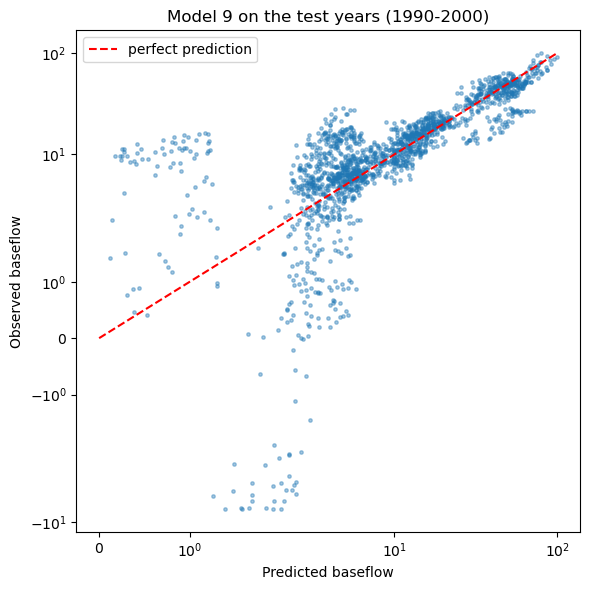

In [ ]:
test["predicted"] = np.expm1(m9.predict(test))

plt.figure(figsize=(6, 6))
plt.scatter(test["predicted"], test["observed"], s=6, alpha=0.4)
lim = [0, max(test["observed"].max(), test["predicted"].max())]
plt.plot(lim, lim, color="red", linestyle="--", label="perfect prediction")
plt.xscale("symlog")
plt.yscale("symlog")
plt.xlabel("Predicted baseflow")
plt.ylabel("Observed baseflow")
plt.title("Model 9 on the test years (1990-2000)")
plt.legend()
plt.tight_layout()
plt.show()

Points near the red line are good predictions. Most points sit close to the line, even though the model never saw these years.

### Checking the errors

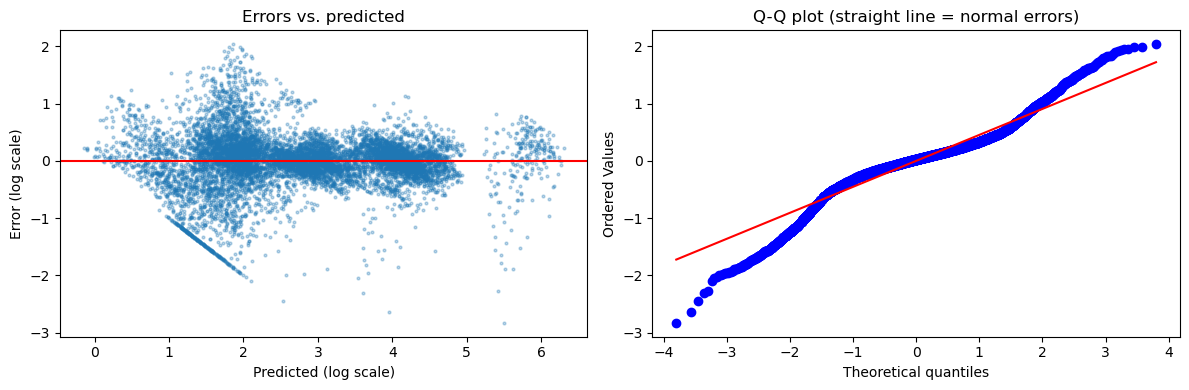

Durbin-Watson: 0.29  (2 = errors not linked month to month)


In [ ]:
resid = m9.resid  # errors on the log scale (training years)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(m9.fittedvalues, resid, s=4, alpha=0.3)
axes[0].axhline(0, color="red")
axes[0].set_xlabel("Predicted (log scale)")
axes[0].set_ylabel("Error (log scale)")
axes[0].set_title("Errors vs. predicted")

import scipy.stats as stats
stats.probplot(resid, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot (straight line = normal errors)")
plt.tight_layout()
plt.show()

print(f"Durbin-Watson: {durbin_watson(resid):.2f}  (2 = errors not linked month to month)")

- **Errors vs. predicted:** the errors are spread out more for small predicted values. Small creeks are harder to predict in percentage terms.
- **Q-Q plot:** the ends curve away from the line, so the errors have heavier tails than a normal distribution. The paper found the same thing (its Fig. 3c).
- **Durbin–Watson is far below 2.** Errors in neighboring months are strongly linked, which means the **p-values are too optimistic**. The model is still fine for predicting, but we should be careful saying "p < 0.001". The paper shows the same problem (its Fig. 3d).

### How far off is each station in the test years?

Positive = predicted too high, negative = predicted too low.

In [ ]:
per_station = (
    test.groupby("station")
        .agg(months=("observed", "size"), mean_observed=("observed", "mean"), mean_predicted=("predicted", "mean"))
)
per_station["% off"] = 100 * (per_station["mean_predicted"] - per_station["mean_observed"]) / per_station["mean_observed"].abs()
per_station.sort_values("% off").round(1)

,months,mean_observed,mean_predicted,% off
station,,,,
171_1508590,90,6.9,1.1,-84.6
138_1434670,129,10.9,4.6,-57.8
178_927790,129,7.1,3.2,-54.5
64_1645870,60,6.2,4.6,-25.3
149_1387150,81,6.7,5.0,-24.9
148_1703950,117,19.4,16.7,-14.2
60_1144270,129,16.8,14.9,-11.3
170_1270990,117,46.0,41.2,-10.5
40_1798990,117,13.1,12.0,-8.0


- Several stations are predicted within about 10%.
- Some stations are predicted much too high or too low in the test years. Their baseflow changed in ways the inputs can't explain (for example, station 178 going negative). The paper had the same problem at some gauges (its Turkey Creek example).

## Part 4: Background research

This section only uses facts stated in the paper (Xu & Valocchi, 2015).

### The river basin

- The Republican River Basin covers parts of **Colorado, Kansas and Nebraska**.
- Growing water demand for **irrigation** and other uses led to a large increase in **groundwater pumping** and a **decline in streamflow**.
- This caused water conflicts and lawsuits between the states.

### The RRCA groundwater model

- To help resolve these conflicts, the **Republican River Compact Administration (RRCA)** developed a groundwater model in 2002 and updates it every year.
- The model covers 1918–2000 on a grid of 1-mile squares, with one time step per month.
- It is used to estimate how groundwater pumping for irrigation affects streamflow.

### Where "observed" baseflow comes from

Baseflow is not measured directly. It is estimated by splitting the total measured streamflow into a surface-water part and a groundwater part. The paper calls these estimates "observations" because no direct measurements of baseflow exist. So our target, `observed`, is itself an estimate.

### How this connects to our data and results

| From the paper | What we saw ourselves |
|---|---|
| Groundwater pumping increased a lot | At the 37 stations we used, the share of months with pumping grows from about 16% in the 1940s to about 58% in the 1980s |
| Pumping is linked to declining streamflow | Model 9: more pumping → less baseflow; cumulative pumping is significant; baseflow declines about 0.8% per year |
| Pumping is for irrigation | Pumping only happens in June–September, when baseflow is lowest (EDA) |
| The paper only used positive baseflow and removed zero periods | Our data still has 232 negative and 1,244 zero values, mostly negative at station 178 |


## Part 5: Comparison with the paper

The paper uses the same river basin and the same test years (1990–2000), so we can compare roughly.

| Model | Test NSE | Test PBIAS |
|---|---|---|
| Paper: RRCA groundwater model alone | 0.83 | +18.13% |
| Paper: groundwater model + random forest correction | 0.93 | +0.08% |
| Paper: groundwater model + SVR correction | 0.93 | +2.30% |
| **Ours: model 9 (linear regression)** | **0.80** | **+3.4%** |

Positive PBIAS means the predictions are too low on average.

Our model's score is close to the paper's groundwater model, with less bias. But this is **not a fair comparison**:

- **Different inputs:** the paper's correction models used the groundwater model's own predicted baseflow and the difference between groundwater level and streambed elevation. Our dataset doesn't include either.
- **Different stations:** the paper used 30 stations with at least 10 years of data, from 1941 to 2000, and removed negative and zero baseflow. We used 37 stations and kept those values.
- **Different method:** the paper predicts the groundwater model's *mistakes* and corrects them. We predict baseflow directly.
- **Units:** the paper reports baseflow in m³/s. Our dataset doesn't state its units, so MAE values can't be compared.

The paper found some of the same problems we did:

- errors are linked from month to month (low Durbin–Watson at every station, its Fig. 3d);
- errors are not bell-shaped (its Fig. 3c);
- some stations change in ways the inputs don't explain (its Turkey Creek example).


## Part 6: Limitations and conclusion

### Limitations

- **Overconfident p-values:** errors are linked month to month (Durbin–Watson about 0.29), so the p-values look more certain than they are.
- **Some stations are predicted badly:** a few rivers changed in the 1990s in ways rain, ET and pumping can't explain.
- **Missing data:** we removed 9 stations (about 28% of rows) because their inputs were missing.
- **Precipitation is yearly:** it can't explain month-to-month changes.
- **Negative baseflow:** we set it to 0 before taking the log, which loses some information at station 178.
- **"Observed" baseflow is an estimate,** not a direct measurement.
- **The year trend assumes a steady decline.** If the cause of the decline changes, the trend won't keep working.

### What we'd try next

- A separate model for each station, since rivers react differently to pumping
- Ridge or Lasso regression, to let each station have its own seasonal pattern without overfitting
- Adding last month's baseflow as an input, if it would be available at prediction time
- Models that account for errors being linked over time

### Conclusion

1. **Which river it is** explains most of the baseflow. The inputs alone are useless without it.
2. Effects work as **percentages** of each river's size, so predicting the **log** of baseflow works much better.
3. Baseflow has **declined about 0.8% per year**, and a model needs that trend to predict the 1990s.
4. **More pumping and more evaporation mean less baseflow; more rain means more.** This matches the paper's description of pumping causing streamflow decline.
5. **Model 9** predicts the 1990s with a test NSE of about 0.80, close to the paper's groundwater model, and adding more features doesn't improve it.

### References

- Xu, T., & Valocchi, A. J. (2015). Data-driven methods to improve baseflow prediction of a regional groundwater model. *Computers & Geosciences*, 85, 124–136.

## Summary

| Step | Test NSE | Lesson |
|---|---|---|
| Inputs only (models 1–2) | below 0 | Useless without knowing the river |
| Station (model 3) | about 0.62 | Which river it is explains most of it |
| Normal scale + month/inputs (4–6) | 0.44–0.59 | Same amount for every river doesn't fit |
| Log scale (7–8) | about 0.60–0.65 | Effects work as percentages |
| **Log + year trend (model 9)** | **about 0.80** | Needs the slow decline to predict the 1990s |
| All features combined | about 0.80 | Extra features repeat what model 9 knows |

**Main model: model 9.** It's simple, its coefficients match the physics, and adding more features doesn't beat it.

**Limits:** the errors are linked month to month (so p-values are too optimistic), and a few stations change in ways the model can't explain.

## Part Seven: Incorporating a History Check

The Republican River was dammed between 148-1952, creating a reservoir so that flooding which occurred on the river and had already destroyed a town would be mitigated. In an effort to attempt to potentially increase accuracy, the following model utilizes information collected in 1953 onwards (after the Harlan County Dam was filled in November 1952).

We will compare the original models, trained on 1939-1989, with models trained only on 1953-1989. Both sets of models predict baseflow for the same test period (1990-2000).

Using the same test observations makes the comparison fair: any change in the scores reflects differences in the training data and fitted models, rather than the test set.

We will evaluate the models using the NSE, MAE, and PBIAS as indicators of performance. We will also compare Durbin-Watson statistics for the training residuals.

### Sources

“Annual Operating Plan: Republican River Basin and Smoky Hill River Basin, 1953 Operations, 1954 Plan of Operation.” Bureau of Reclamation, U.S. Department of the Interior, 1953, https://www.usbr.gov/gp//aop/niobrara/1953krp.pdf

*USACE Dam Safety Facts for Harlan County Dam*. U.S. Army Corps of Engineers, 2018, https://usace.contentdm.oclc.org/digital/api/collection/p16021coll11/id/2393/download.

In [28]:
# Creating independent training and test datasets to keep data clean
history_train = df[
    (df["year"] >= 1953) & (df["year"] <=1989)
].copy()

# Use only the stations represented in new training period
history_stations = history_train["station"].unique()
common_stations = set(train["station"].unique()) & set(history_stations)

history_test = test[
    test["station"].isin(common_stations)
].copy()

original_train_history = train.copy()
print(f"Original training rows: {len(original_train_history):,}")
print(f"Post-1953 training rows: {len(history_train):,}")
print(f"Common test rows: {len(common_stations)}")
print(
    f"Test period: {history_test["year"].min()}-"
    f"{history_test["year"].max()}"
)

Original training rows: 9,511
Post-1953 training rows: 6,633
Common test rows: 26
Test period: 1990-2000


In [29]:
# 2. Define the same ten models used in the original ladder
history_formulas = {
    "0 average only": ("1", False),
    "1 rain + ET + pumping": ("et + precip + pump", False),
    "2 + location (x, y)": (
        "et + precip + pump + x + y", False
    ),
    "3 station": ("C(station)", False),
    "4 station + month": (
        "C(station) + C(month)", False
    ),
    "5 station + month + inputs": (
        "C(station) + C(month) + et + precip + pump", False
    ),
    "6 + year trend": (
        "C(station) + C(month) + et + precip + pump + t", False
    ),
    "7 LOG station + month": (
        "C(station) + C(month)", True
    ),
    "8 LOG station + month + inputs": (
        "C(station) + C(month) + et + precip + pump", True
    ),
    "9 LOG + year trend": (
        "C(station) + C(month) + et + precip + pump + t", True
    ),
}

In [30]:
# 3. Fit and evaluate each model using a local results dictionary
history_models = {}
history_results = []

for name, (formula, use_log) in history_formulas.items():

    target = "log_observed" if use_log else "observed"

    # Original training period: 1939–1989
    original_model = smf.ols(
        f"{target} ~ {formula}",
        data=original_train_history
    ).fit()

    # New training period: 1953–1989
    post_model = smf.ols(
        f"{target} ~ {formula}",
        data=history_train
    ).fit()

    # Convert log predictions back to baseflow units
    back = np.expm1 if use_log else (lambda v: v)

    original_pred = back(original_model.predict(history_test))
    post_pred = back(post_model.predict(history_test))

    actual = history_test["observed"]

    original_scores = scores(actual, original_pred)
    post_scores = scores(actual, post_pred)

    history_models[name] = {
        "original": original_model,
        "post1952": post_model,
    }

    history_results.append({
        "model": name,
        "original_NSE": original_scores["NSE"],
        "post1952_NSE": post_scores["NSE"],
        "change_NSE": post_scores["NSE"] - original_scores["NSE"],
        "original_MAE": original_scores["MAE"],
        "post1952_MAE": post_scores["MAE"],
        "change_MAE": post_scores["MAE"] - original_scores["MAE"],
        "original_PBIAS": original_scores["PBIAS"],
        "post1952_PBIAS": post_scores["PBIAS"],
        "original_DW": durbin_watson(original_model.resid),
        "post1952_DW": durbin_watson(post_model.resid),
    })

history_comparison = (
    pd.DataFrame(history_results)
    .set_index("model")
)

display(history_comparison.round(3))

,original_NSE,post1952_NSE,change_NSE,original_MAE,post1952_MAE,change_MAE,original_PBIAS,post1952_PBIAS,original_DW,post1952_DW
model,,,,,,,,,,
0 average only,-1.224,-0.101,1.123,23.145,14.741,-8.404,-110.961,-31.897,0.047,0.029
1 rain + ET + pumping,-1.734,-0.084,1.651,24.317,14.591,-9.726,-107.033,-29.485,0.054,0.029
"2 + location (x, y)",-2.493,-0.142,2.351,27.201,15.438,-11.763,-118.295,-18.487,0.053,0.037
3 station,0.623,0.669,0.046,6.475,6.099,-0.376,-19.921,-14.221,0.254,0.187
4 station + month,0.590,0.696,0.106,7.797,6.101,-1.696,-20.630,-14.093,0.251,0.160
5 station + month + inputs,0.441,0.684,0.243,9.046,6.349,-2.697,-21.270,-13.891,0.261,0.179
6 + year trend,0.461,0.641,0.180,8.855,7.402,-1.453,13.162,18.539,0.263,0.194
7 LOG station + month,0.650,0.697,0.047,6.095,5.729,-0.365,-16.347,-11.896,0.249,0.295
8 LOG station + month + inputs,0.602,0.669,0.067,6.380,5.963,-0.417,-18.634,-14.342,0.280,0.316


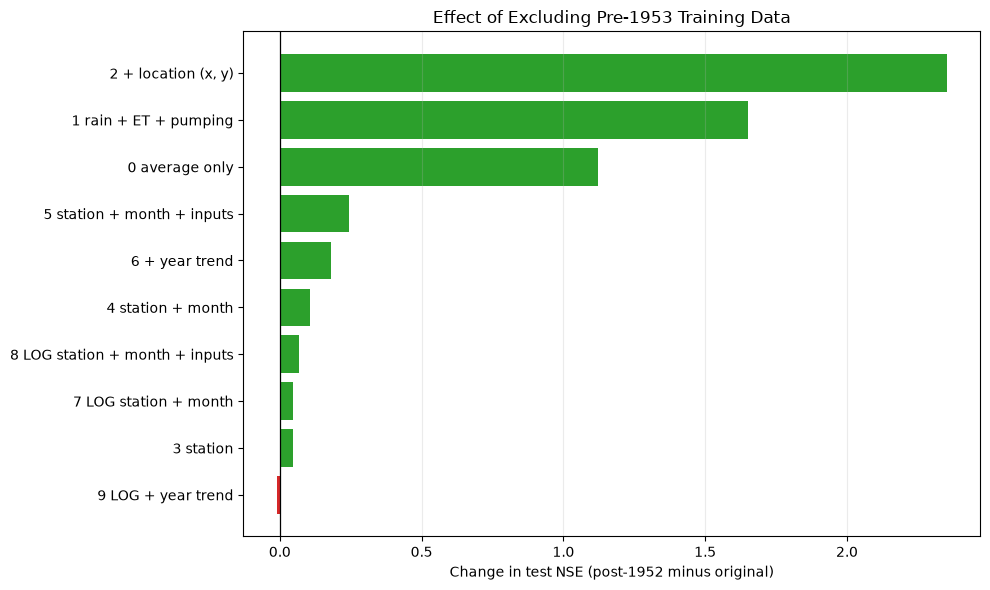

In [31]:
# Compare the change in test NSE for all ten models

plot_data = history_comparison["change_NSE"].sort_values()

colors = [
    "tab:green" if value > 0 else "tab:red"
    for value in plot_data
]

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(plot_data.index, plot_data.values, color=colors)
ax.axvline(0, color="black", linewidth=0.9)

ax.set_xlabel("Change in test NSE (post-1952 minus original)")
ax.set_title("Effect of Excluding Pre-1953 Training Data")
ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()


,NSE,MAE,PBIAS
Original training (1939–1989),0.7983,4.8725,3.3604
Post-1952 training (1953–1989),0.7874,4.9627,0.4799


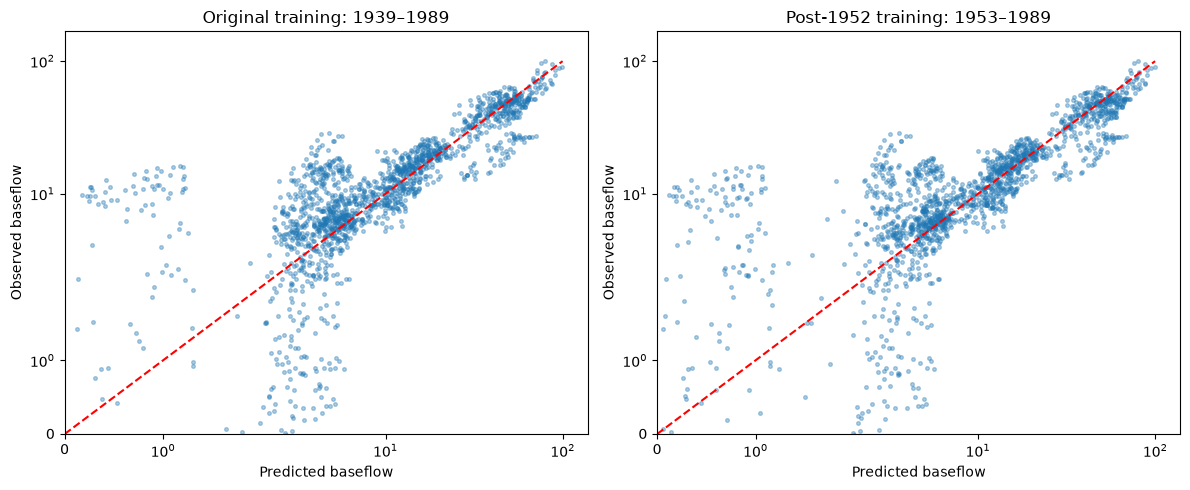

In [32]:
# Compare predictions from the original and post-1952 model 9

m9_original_history = history_models[
    "9 LOG + year trend"
]["original"]

m9_post1952 = history_models[
    "9 LOG + year trend"
]["post1952"]

actual = history_test["observed"]

pred_original = np.expm1(
    m9_original_history.predict(history_test)
)

pred_post1952 = np.expm1(
    m9_post1952.predict(history_test)
)

# Compare the three evaluation metrics
model9_history_scores = pd.DataFrame({
    "Original training (1939–1989)": scores(
        actual, pred_original
    ),
    "Post-1952 training (1953–1989)": scores(
        actual, pred_post1952
    ),
}).T

display(model9_history_scores.round(4))

# Plot actual versus predicted baseflow
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

predictions = [
    (pred_original, "Original training: 1939–1989"),
    (pred_post1952, "Post-1952 training: 1953–1989"),
]

upper = max(
    actual.max(),
    pred_original.max(),
    pred_post1952.max()
)

for ax, (pred, title) in zip(axes, predictions):
    ax.scatter(pred, actual, s=7, alpha=0.35)
    ax.plot([0, upper], [0, upper], "r--")
    ax.set_xscale("symlog")
    ax.set_yscale("symlog")
    ax.set_xlim(left=0)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Predicted baseflow")
    ax.set_ylabel("Observed baseflow")
    ax.set_title(title)

plt.tight_layout()
plt.show()

In [33]:
# Find the best model by test NSE under each training setup

best_original = history_comparison["original_NSE"].idxmax()
best_post1952 = history_comparison["post1952_NSE"].idxmax()

print("Best model using original training data:")
print(best_original)
print(
    f"Test NSE: "
    f"{history_comparison.loc[best_original, 'original_NSE']:.3f}"
)

print("\nBest model using post-1952 training data:")
print(best_post1952)
print(
    f"Test NSE: "
    f"{history_comparison.loc[best_post1952, 'post1952_NSE']:.3f}"
)

print("\nChange in test NSE for model 9:")
print(
    f"{history_comparison.loc['9 LOG + year trend', 'change_NSE']:+.3f}"
)

print("\nChange in test MAE for model 9:")
print(
    f"{history_comparison.loc['9 LOG + year trend', 'change_MAE']:+.3f}"
)

Best model using original training data:
9 LOG + year trend
Test NSE: 0.798

Best model using post-1952 training data:
9 LOG + year trend
Test NSE: 0.787

Change in test NSE for model 9:
-0.011

Change in test MAE for model 9:
+0.090


## History Check - Summary and Conclusion

The goal was to determine if this would improve the baseflow prediction model accuracy. Overall, excluding pre-1953 data improved the performance on most of the models but it did not improve our best-performing model.

Model 9, our log-scale linear regression model incorporating station, month, precipitation, evapotranspiration, pumping, and a year trend, performed best under both training approaches. However, its NSE decreased slightly from 0.798 to 0.787, while its MAE increased from 4.873 to 4.963. These changes indicate a small reduction in predictive accuracy after excluding pre-1952 data. On the other hand, its PBIAS improved from +3.36% to +0.48%, meaning that its predictions were more balanced overall with less systematic underprediction. Therefore it was slightly worse in overall accuracy but had lower overall bias.

This suggests that the pre-1952 observations contain useful information for predicting baseflow. Though the dam may have influenced river conditions, simply excluding all earlier observations did not improve model 9's predictive accuracy. The improvements seen in other models suggest that the historical data may affect different model structures in other ways.

It should be noted that these findings do not establish whether the dam caused the observed differences, but they provide a useful starting point for understanding how historical changes may affect baseflow prediction.